# Exploring the bank marketing calls

A bank called thousands of people and asked them to open a **term deposit** (a savings account that locks money away for a set time, usually at a higher interest rate).

Each row is one phone call. The last column, `y`, is the outcome: `yes` if the person subscribed, `no` if they did not.

This notebook is the look-around step. It does not train the model. Training lives in `train.py`, so the same steps can run outside a notebook (in a test, or in the cloud).

**Analogy:** the notebook is walking the shop floor before you design the machine. `train.py` is the machine.

## How this notebook connects to the other files

- `ingest.py` downloads and loads the CSV. We call it instead of copying the download code into this notebook.
- `features.py` knows which columns are cheating. We use it at the end to show the table the model will actually see.
- `config.py` holds the column names so this notebook and the trainer cannot drift apart.

Run this notebook from the project folder, or just run the cells: the next cell finds the project folder either way.

In [1]:
import sys
from pathlib import Path

# A notebook's starting folder is often notebooks/, not the project root.
# Python will not find ingest.py unless the project root is on the search path.
project_root = Path.cwd()
if not (project_root / "ingest.py").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import pandas as pd

from config import LEAKAGE_COLUMNS, UNUSED_COLUMNS
from features import add_engineered_columns
from ingest import ingest

pd.set_option("display.max_columns", 30)
print(f"Project folder: {project_root}")

Matplotlib is building the font cache; this may take a moment.


Project folder: C:\Users\mamoh\Downloads\Projects\ai-apps\bank-term-deposit-ml


## Load the table

`ingest()` downloads the UCI zip the first time, unpacks the zip-inside-a-zip, and returns a table. The second run reuses the file on disk.

In [2]:
calls = ingest()
print(f"Rows: {len(calls):,}")
print(f"Columns: {list(calls.columns)}")
calls.head()

Rows: 45,211
Columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## Most people said no

This is the most important picture in the notebook.

If 88 of 100 people say no, a model that *always* says no is 88% accurate and never finds a customer. Accuracy is the wrong score. The training script uses average precision instead, which cares about finding the rare yes rows. That choice is decision 8 in `DECISIONS.md`.

y
no     39922
yes     5289
Name: count, dtype: int64
y
no     88.3%
yes    11.7%
Name: proportion, dtype: object


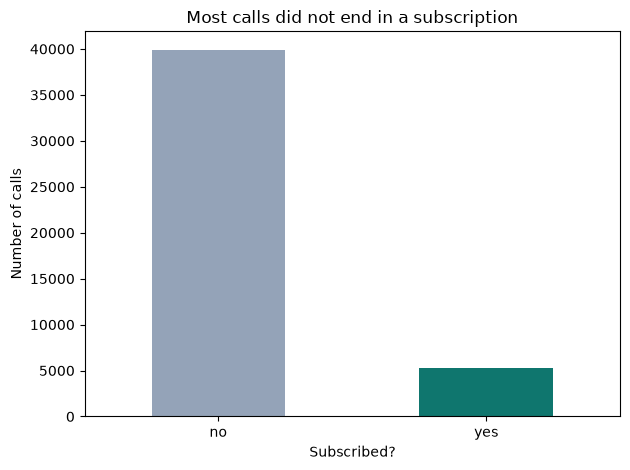

In [3]:
outcome_counts = calls["y"].value_counts()
outcome_rate = calls["y"].value_counts(normalize=True)
print(outcome_counts)
print((outcome_rate * 100).round(1).astype(str) + "%")

outcome_counts.plot(kind="bar", color=["#94a3b8", "#0f766e"], rot=0)
plt.title("Most calls did not end in a subscription")
plt.xlabel("Subscribed?")
plt.ylabel("Number of calls")
plt.tight_layout()
plt.show()

## Missing values, and the word "unknown"

This file barely uses blank cells. It uses the word `unknown` instead, especially for the contact channel and the previous-campaign outcome.

`unknown` is information. It often means "we never reached a real channel" or "there was no previous campaign." We keep it as its own category. Filling it with the most common job would hide that signal.

In [4]:
print("Blank cells per column:")
print(calls.isna().sum())
print()
print("How often the word 'unknown' appears:")
for column in calls.select_dtypes(include="object").columns:
    unknown_count = int((calls[column].astype(str).str.lower() == "unknown").sum())
    if unknown_count:
        print(f"  {column}: {unknown_count:,}")

Blank cells per column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

How often the word 'unknown' appears:
  job: 288
  education: 1,857
  contact: 13,020
  poutcome: 36,959


## The cheating column: `duration`

`duration` is how many seconds the call already lasted.

A banker asking "should I dial this number?" does not know that number yet. If we train on it, the model learns "long calls tend to be successful calls," which is true and useless. You only learn the length after you have already paid for the call.

The chart below shows why the column is tempting. Then we drop it. `train.py` drops it too, via `features.py`.

Median call length in seconds:
y
no     164.0
yes    426.0
Name: duration, dtype: float64


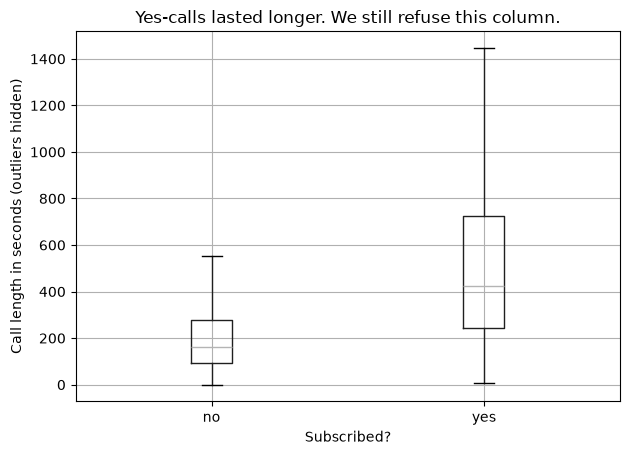

Leakage columns the trainer drops: ['duration']


In [5]:
duration_by_outcome = calls.groupby("y")["duration"].median()
print("Median call length in seconds:")
print(duration_by_outcome)

calls.boxplot(column="duration", by="y", showfliers=False)
plt.suptitle("")
plt.title("Yes-calls lasted longer. We still refuse this column.")
plt.xlabel("Subscribed?")
plt.ylabel("Call length in seconds (outliers hidden)")
plt.tight_layout()
plt.show()
print(f"Leakage columns the trainer drops: {LEAKAGE_COLUMNS}")

## `-1` is a code, not a number of days

`pdays` is "how many days since we last called this person, in an earlier campaign."

`-1` means "we never called them before." If a model treats `-1` as a number, it thinks those people were contacted in the future. `features.py` turns that code into a yes/no column named `never_contacted_before`.

In [6]:
never_called = calls["pdays"] < 0
print(f"Never contacted before this campaign: {int(never_called.sum()):,} of {len(calls):,}")
print("Subscription rate if never contacted:", round(float((calls.loc[never_called, "y"] == "yes").mean()), 3))
print("Subscription rate if contacted before:", round(float((calls.loc[~never_called, "y"] == "yes").mean()), 3))

Never contacted before this campaign: 36,954 of 45,211
Subscription rate if never contacted: 0.092
Subscription rate if contacted before: 0.231


## Who says yes more often?

These rates are not the model. They are a flashlight. Students and retired clients subscribe more often than blue-collar clients in this file. That can be real, or it can be "the bank already chose who to call." Either way, the model is allowed to see `job`, because the bank knows the job *before* the call.

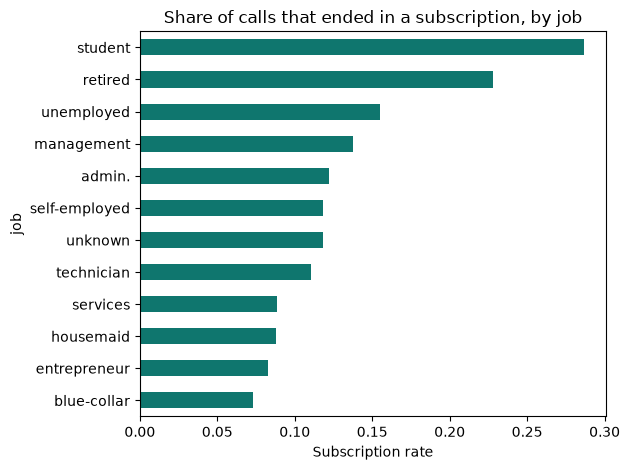

job
blue-collar      0.073
entrepreneur     0.083
housemaid        0.088
services         0.089
technician       0.111
unknown          0.118
self-employed    0.118
admin.           0.122
management       0.138
unemployed       0.155
retired          0.228
student          0.287
Name: subscribed, dtype: float64

In [7]:
job_rate = (
    calls.assign(subscribed=calls["y"].eq("yes"))
    .groupby("job")["subscribed"]
    .mean()
    .sort_values()
)
job_rate.plot(kind="barh", color="#0f766e")
plt.title("Share of calls that ended in a subscription, by job")
plt.xlabel("Subscription rate")
plt.tight_layout()
plt.show()
job_rate.round(3)

## Month is a planning signal. Day-of-month is not.

May has a huge number of calls and a low success rate. December has few calls and a high rate. A planner can choose a month.

The day of the month (`day`) is a leftover of the old campaign calendar. We drop it so the model cannot memorize "the 19th was lucky." That is decision 3 in `DECISIONS.md`.

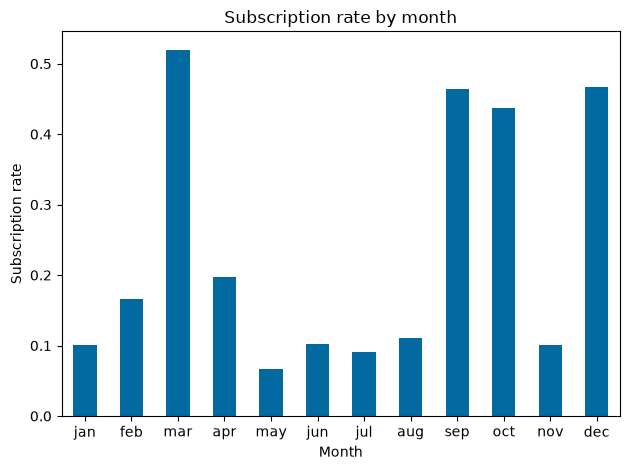

Columns dropped as brittle, not as leakage: ['day']


In [8]:
month_order = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_rate = (
    calls.assign(subscribed=calls["y"].eq("yes"))
    .groupby("month")["subscribed"]
    .mean()
    .reindex(month_order)
)
month_rate.plot(kind="bar", color="#0369a1", rot=0)
plt.title("Subscription rate by month")
plt.xlabel("Month")
plt.ylabel("Subscription rate")
plt.tight_layout()
plt.show()
print(f"Columns dropped as brittle, not as leakage: {UNUSED_COLUMNS}")

## What the model is allowed to see

The next cell runs the same function `train.py` runs. Compare the columns to the raw table above.

Gone: `duration`, `day`, and `y` (the answer).
New: `never_contacted_before` and `contacts_already_made`.

After this notebook, the next command is:

```powershell
python main.py train
```

That compares logistic regression, a random forest, and gradient boosting, and writes `reports/results.md`.

In [9]:
prepared = add_engineered_columns(calls)
print("Raw columns:", list(calls.columns))
print("Model columns:", list(prepared.columns))
prepared.head()

Raw columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']
Model columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'month', 'pdays', 'previous', 'poutcome', 'contacts_already_made', 'never_contacted_before']


,age,job,marital,education,default,balance,housing,loan,contact,month,pdays,previous,poutcome,contacts_already_made,never_contacted_before
0,58.0,management,married,tertiary,no,2143.0,yes,no,unknown,may,0.0,0.0,unknown,0.0,1.0
1,44.0,technician,single,secondary,no,29.0,yes,no,unknown,may,0.0,0.0,unknown,0.0,1.0
2,33.0,entrepreneur,married,secondary,no,2.0,yes,yes,unknown,may,0.0,0.0,unknown,0.0,1.0
3,47.0,blue-collar,married,unknown,no,1506.0,yes,no,unknown,may,0.0,0.0,unknown,0.0,1.0
4,33.0,unknown,single,unknown,no,1.0,no,no,unknown,may,0.0,0.0,unknown,0.0,1.0
